# Condition 04 - EA-driven island migration: identifiability results

Results of the full command-line run (`python test_identifiability.py --stage ...`). This
notebook runs **no simulations**; it only loads the cached outputs in `output/`.
The methods are explained, and can be rerun at small scale, in `condition4_tests.ipynb`.

**Model.** EA = additive genetics + unique environment; no AM, no VT, no shared environment.
5 islands; each generation a fraction `move_p` of each sex per island migrates and is sorted
onto islands by EA phenotype. Random founders, `n_gen` generations in total; the last 3 are
observed.

| parameter | range | value when fixed |
|---|---|---|
| `move_p` | 0.01 - 0.70 | 0.40 |
| `n_gen` | 3 - 10 (integer) | 6 |
| `vg1` | 0.20 - 0.80 | 0.50 |
| `prop_h2_latent1` | 0.30 - 0.90 | 0.60 |

**Simulation size:** population 4,000 (5 islands), 300 causal variants. **Features:** PGS1 and
Y1 correlations for 15 relationship types (HSFS is always empty and PPSCC is empty when
`n_gen = 3`, so both are dropped), i.e. 30 features.

**Question:** for each of the 15 subsets of parameters left free (the rest fixed / known),
are *all* free parameters identified at the same time?

**Pass criteria (per parameter)**

| method | identified when |
|---|---|
| Jacobian (local, at baseline) | relative sensitivity ≥ 0.15, max \|cos\| ≤ 0.90, condition number ≤ 30, Cramér-Rao SE ≤ 0.15 × range |
| Ridge recovery (5-fold CV, 2,000 sims) | R² ≥ 0.5 |
| NPE (held-out 15%) | R² ≥ 0.5 and posterior SD ≤ 0.6 × prior SD |

**NPE estimator.** `n_gen` is a count, so its posterior is a **categorical distribution**
(a classifier gives p(n_gen | data) for every value 3-10), and the continuous parameters get a
neural spline flow conditioned on the data *and* n_gen (`npe_mixed.py`). The standardised
correlations go straight into the flow, without the dropout embedding network; Section 7 shows
this does not hurt (it helps).

For ridge and NPE the parameters outside the subset are given to the model as **known
inputs**, which is equivalent to fixing them but averaged over their range; Section 6 checks
this against truly fixing them.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

OUT = Path.cwd() / "output"
PARAMS = ["move_p", "n_gen", "vg1", "prop_h2_latent1"]
pd.set_option("display.width", 160)

traj = pd.read_csv(OUT / "trajectory.csv")
S = pd.read_csv(OUT / "jacobian.csv", index_col=0)
sd = pd.read_csv(OUT / "jacobian_noise_sd.csv", index_col=0)["noise_sd"]
long = pd.read_csv(OUT / "subsets_long.csv")
comp = pd.read_csv(OUT / "subsets_compare.csv")
maximal = json.load(open(OUT / "maximal_subsets.json"))
order = comp.sort_values(["size", "subset"], ascending=[False, True])["subset"].tolist()
design = pd.read_csv(OUT / "design.csv")
# features used by all methods: those missing in <= 5% of design rows
feats = [f for f in S.index if f in design.columns and design[f].isna().mean() <= 0.05]
S, sd = S.loc[feats], sd.loc[feats]
print(f"design: {len(design)} simulations, {len(feats)} features")

design: 2000 simulations, 30 features


## 1. Stratification over generations

Between-island share of variance (variance of island means / total variance) for the EA
phenotype and the EA PGS, by `move_p`, with the other parameters at baseline (average of 3
runs). Both `move_p` and generation number change how strongly islands sort on EA, which is
the signal that should make `move_p` and `n_gen` estimable.

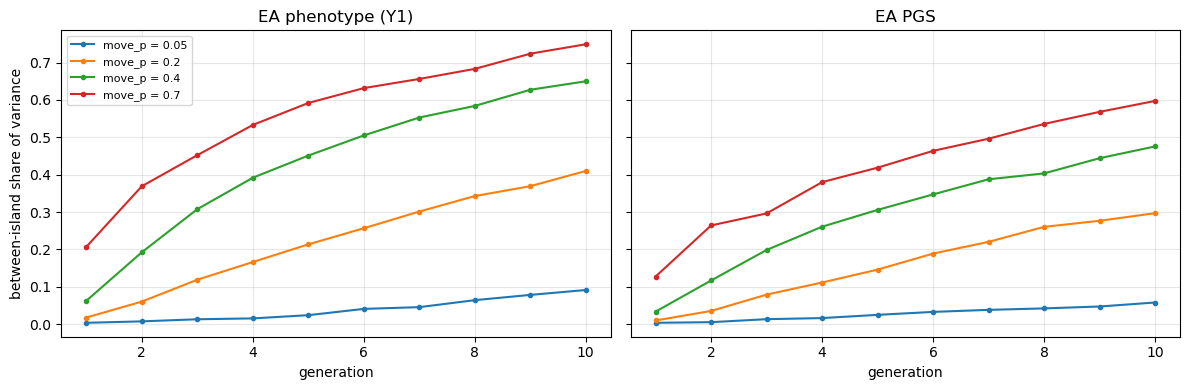

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for m, sub in traj.groupby("move_p"):
    axes[0].plot(sub["gen"], sub["between_share_Y1"], marker="o", ms=3, label=f"move_p = {m}")
    axes[1].plot(sub["gen"], sub["between_share_PGS1"], marker="o", ms=3, label=f"move_p = {m}")
axes[0].set_title("EA phenotype (Y1)"); axes[1].set_title("EA PGS")
for ax in axes:
    ax.set_xlabel("generation"); ax.grid(alpha=0.3)
axes[0].set_ylabel("between-island share of variance"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Jacobian at the baseline

Each entry is the change in a correlation across the parameter's full range, divided by that
correlation's single-run noise SD (from 20 baseline replicates). Large absolute values = strong,
detectable effects.

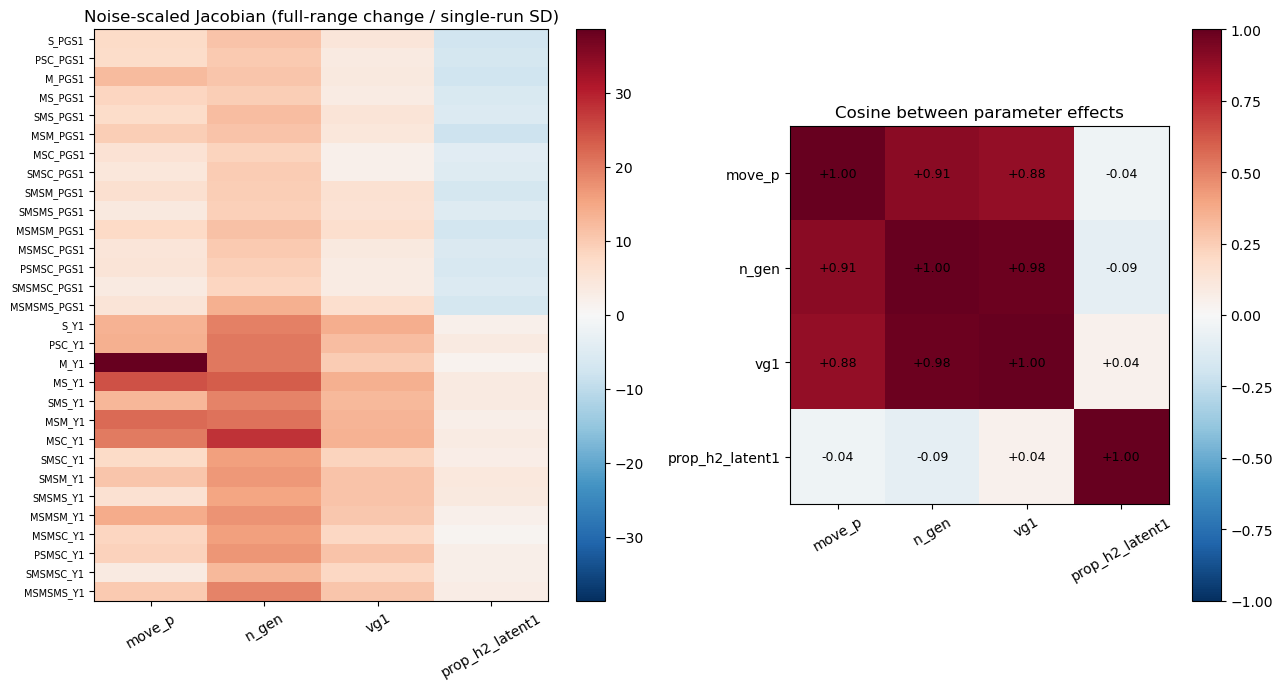

In [3]:
Jw = S.div(sd, axis=0)
vmax = np.abs(Jw.values).max()
fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [1.2, 1]})
im = axes[0].imshow(Jw.values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[0].set_xticks(range(Jw.shape[1])); axes[0].set_xticklabels(Jw.columns, rotation=30)
axes[0].set_yticks(range(Jw.shape[0])); axes[0].set_yticklabels(Jw.index, fontsize=7)
axes[0].set_title("Noise-scaled Jacobian (full-range change / single-run SD)")
fig.colorbar(im, ax=axes[0])

M = Jw.to_numpy(); Mn = M / np.linalg.norm(M, axis=0)
C = Mn.T @ Mn
im2 = axes[1].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(4)); axes[1].set_xticklabels(Jw.columns, rotation=30)
axes[1].set_yticks(range(4)); axes[1].set_yticklabels(Jw.columns)
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, f"{C[i, j]:+.2f}", ha="center", va="center", fontsize=9)
axes[1].set_title("Cosine between parameter effects")
fig.colorbar(im2, ax=axes[1]); plt.tight_layout(); plt.show()

**Cramér-Rao SE per subset** (in units of each parameter's range; ≤ 0.15 passes). Blank =
parameter is fixed in that subset.

In [4]:
crb = long.pivot(index="subset", columns="parameter", values="jac_crb_se").reindex(order)[PARAMS]
crb.style.format("{:.3f}", na_rep="").background_gradient(cmap="Reds", vmin=0, vmax=0.3)

parameter,move_p,n_gen,vg1,prop_h2_latent1
subset,,,,
move_p+n_gen+vg1+prop_h2_latent1,0.035,0.092,0.146,0.052
move_p+n_gen+prop_h2_latent1,0.034,0.028,,0.038
move_p+n_gen+vg1,0.034,0.067,0.106,
move_p+vg1+prop_h2_latent1,0.030,,0.045,0.038
n_gen+vg1+prop_h2_latent1,,0.079,0.142,0.051
move_p+n_gen,0.034,0.028,,
move_p+prop_h2_latent1,0.014,,,0.038
move_p+vg1,0.030,,0.044,
n_gen+prop_h2_latent1,,0.012,,0.038


## 3. Ridge recovery R² per subset

In [5]:
def heat(col, title, vmin=0, vmax=1, cmap="RdYlGn", fmt="{:.2f}"):
    tab = long.pivot(index="subset", columns="parameter", values=col).reindex(order)[PARAMS]
    return tab.style.format(fmt, na_rep="").background_gradient(cmap=cmap, vmin=vmin, vmax=vmax).set_caption(title)

heat("ridge_r2", "Ridge 5-fold CV R² (≥ 0.5 passes)")

parameter,move_p,n_gen,vg1,prop_h2_latent1
subset,,,,
move_p+n_gen+vg1+prop_h2_latent1,0.96,0.65,0.78,0.72
move_p+n_gen+prop_h2_latent1,0.96,0.69,,0.72
move_p+n_gen+vg1,0.96,0.65,0.78,
move_p+vg1+prop_h2_latent1,0.97,,0.80,0.72
n_gen+vg1+prop_h2_latent1,,0.75,0.78,0.72
move_p+n_gen,0.96,0.69,,
move_p+prop_h2_latent1,0.97,,,0.72
move_p+vg1,0.97,,0.80,
n_gen+prop_h2_latent1,,0.79,,0.72


## 4. NPE per subset

In [6]:
display(heat("npe_r2", "NPE test R² of posterior mean (≥ 0.5 passes)"))
display(heat("npe_sd_ratio", "NPE posterior SD / prior SD (≤ 0.6 passes)", cmap="RdYlGn_r"))

parameter,move_p,n_gen,vg1,prop_h2_latent1
subset,,,,
move_p+n_gen+vg1+prop_h2_latent1,0.98,0.79,0.84,0.81
move_p+n_gen+prop_h2_latent1,0.98,0.83,,0.81
move_p+n_gen+vg1,0.98,0.80,0.84,
move_p+vg1+prop_h2_latent1,0.99,,0.87,0.81
n_gen+vg1+prop_h2_latent1,,0.89,0.84,0.80
move_p+n_gen,0.98,0.82,,
move_p+prop_h2_latent1,0.99,,,0.81
move_p+vg1,0.99,,0.87,
n_gen+prop_h2_latent1,,0.90,,0.78


parameter,move_p,n_gen,vg1,prop_h2_latent1
subset,,,,
move_p+n_gen+vg1+prop_h2_latent1,0.13,0.41,0.40,0.40
move_p+n_gen+prop_h2_latent1,0.13,0.33,,0.39
move_p+n_gen+vg1,0.13,0.40,0.41,
move_p+vg1+prop_h2_latent1,0.09,,0.34,0.39
n_gen+vg1+prop_h2_latent1,,0.32,0.41,0.40
move_p+n_gen,0.19,0.36,,
move_p+prop_h2_latent1,0.07,,,0.37
move_p+vg1,0.08,,0.33,
n_gen+prop_h2_latent1,,0.25,,0.42


### The n_gen posterior

For every subset with `n_gen` free: how often the posterior mode is the true count, the average
log-probability given to the true count (higher is better; a flat posterior over 8 values gives
log(1/8) = -2.08), and 90% interval coverage. Below, posteriors for a few held-out simulations
(all four parameters free).

,npe_r2,npe_mode_acc,npe_logscore,npe_cover90,npe_sd_ratio
subset,,,,,
move_p+n_gen+vg1+prop_h2_latent1,0.794,0.467,-1.203,0.973,0.407
move_p+n_gen+prop_h2_latent1,0.828,0.517,-1.058,0.973,0.335
move_p+n_gen+vg1,0.796,0.477,-1.194,0.977,0.398
n_gen+vg1+prop_h2_latent1,0.889,0.580,-0.957,0.983,0.318
move_p+n_gen,0.819,0.510,-1.100,0.987,0.364
n_gen+prop_h2_latent1,0.903,0.660,-0.814,0.977,0.247
n_gen+vg1,0.880,0.573,-0.964,0.983,0.315
n_gen,0.898,0.637,-0.850,0.970,0.250


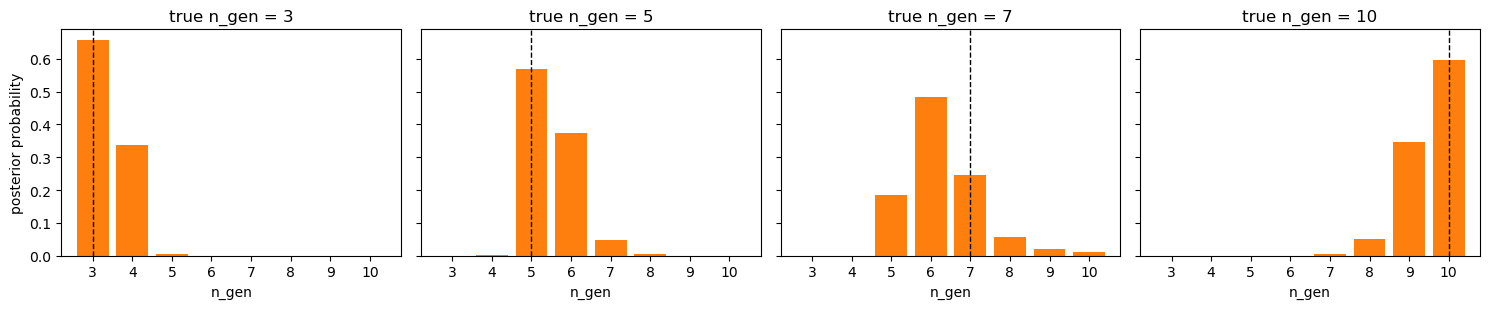

In [7]:
ng = long[long["parameter"] == "n_gen"].set_index("subset").reindex([s for s in order if "n_gen" in s])
display(ng[["npe_r2", "npe_mode_acc", "npe_logscore", "npe_cover90", "npe_sd_ratio"]].round(3))

z = np.load(OUT / "npe" / "+".join(PARAMS) / "count_pmf.npz")
pmf, true, vals = z["pmf"], z["true"].astype(int), z["values"]
picks = [int(np.where(true == g)[0][0]) for g in (3, 5, 7, 10)]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, i in zip(axes, picks):
    ax.bar(vals, pmf[i], color="tab:orange")
    ax.axvline(true[i], color="k", ls="--", lw=1)
    ax.set_title(f"true n_gen = {true[i]}"); ax.set_xticks(vals); ax.set_xlabel("n_gen")
axes[0].set_ylabel("posterior probability")
plt.tight_layout(); plt.show()

### Predictions vs true

Posterior mean against the true value on the held-out set (error bars = posterior SD), for the
model with all four parameters free and for the largest subsets that pass under NPE.

**Free: move_p, n_gen, vg1, prop_h2_latent1**

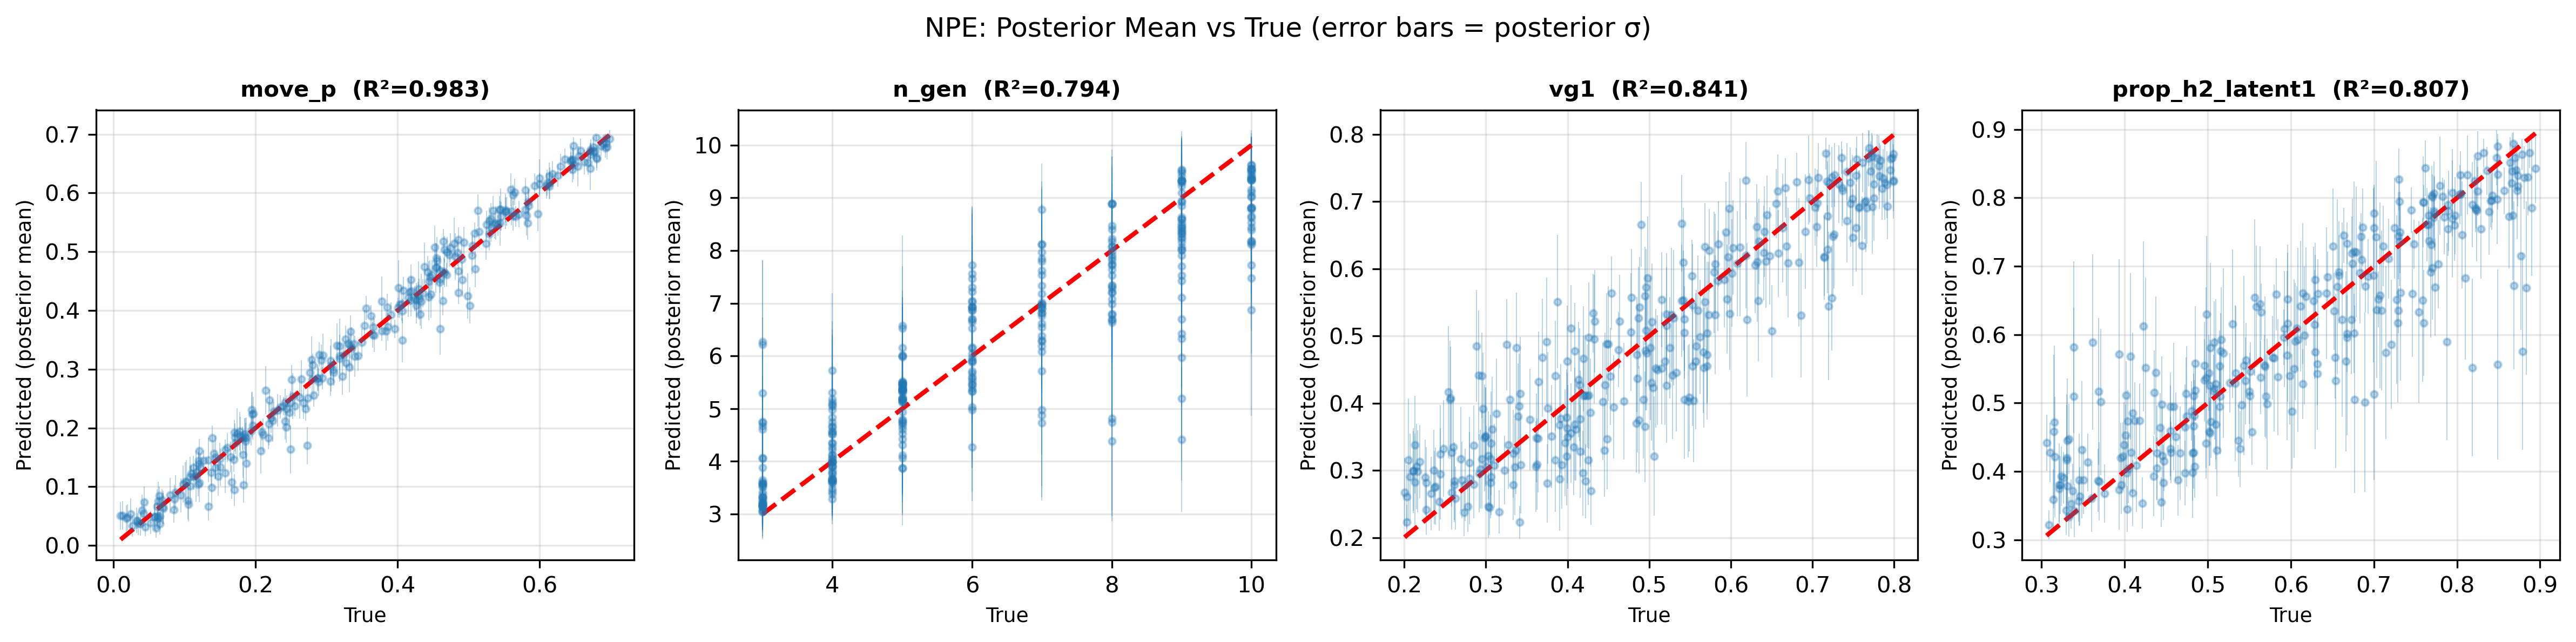

In [8]:
to_show = ["+".join(PARAMS)] + [s for s in maximal["npe_all"] if s != "+".join(PARAMS)]
for s in to_show:
    display(Markdown(f"**Free: {s.replace('+', ', ')}**"))
    display(Image(filename=str(OUT / "npe" / s / "predictions_vs_true.png"), width=1000))

## 5. Comparison: which subsets are jointly identified?

`*_all` = every free parameter in the subset passes that method. `all_methods` = passes all three.

In [9]:
cols = ["subset", "size", "jac_all", "ridge_all", "npe_all", "all_methods",
        "jac_max_crb", "ridge_min_r2", "npe_min_r2", "npe_max_sd_ratio"]
tab = comp[cols].set_index("subset").reindex(order)
def mark(v):
    return "background-color: #c8e6c9" if v is True else ("background-color: #ffcdd2" if v is False else "")
tab.style.format({"jac_max_crb": "{:.3f}", "ridge_min_r2": "{:.2f}", "npe_min_r2": "{:.2f}",
                  "npe_max_sd_ratio": "{:.2f}"}).map(mark, subset=["jac_all", "ridge_all", "npe_all", "all_methods"])

,size,jac_all,ridge_all,npe_all,all_methods,jac_max_crb,ridge_min_r2,npe_min_r2,npe_max_sd_ratio
subset,,,,,,,,,
move_p+n_gen+vg1+prop_h2_latent1,4,False,True,True,False,0.146,0.65,0.79,0.41
move_p+n_gen+prop_h2_latent1,3,False,True,True,False,0.038,0.69,0.81,0.39
move_p+n_gen+vg1,3,False,True,True,False,0.106,0.65,0.80,0.41
move_p+vg1+prop_h2_latent1,3,True,True,True,True,0.045,0.72,0.81,0.39
n_gen+vg1+prop_h2_latent1,3,False,True,True,False,0.142,0.72,0.80,0.41
move_p+n_gen,2,False,True,True,False,0.034,0.69,0.82,0.36
move_p+prop_h2_latent1,2,True,True,True,True,0.038,0.72,0.81,0.37
move_p+vg1,2,True,True,True,True,0.044,0.80,0.87,0.33
n_gen+prop_h2_latent1,2,True,True,True,True,0.038,0.72,0.78,0.42


In [10]:
rows = [{"method": k, "largest jointly identified subsets": ";  ".join(s.replace("+", ", ") for s in v) or "(none)"}
        for k, v in maximal.items()]
pd.DataFrame(rows)

,method,largest jointly identified subsets
0,jac_all,"move_p, vg1, prop_h2_latent1; n_gen, prop_h2_..."
1,ridge_all,"move_p, n_gen, vg1, prop_h2_latent1"
2,npe_all,"move_p, n_gen, vg1, prop_h2_latent1"
3,all_methods,"move_p, vg1, prop_h2_latent1; n_gen, prop_h2_..."


## 6. Check: "known input" vs truly fixed

For the best 3-parameter subset, 600 new simulations were run with the 4th parameter truly fixed
at its baseline value, and NPE was trained on them. The same NPE was trained on 600 rows of the
main design with the 4th parameter given as a known input. Similar R² means the shortcut used
above is a fair stand-in for fixing.

In [11]:
fc = pd.read_csv(OUT / "fixcheck.csv")
fc.pivot(index="parameter", columns="mode", values=["npe_r2", "npe_sd_ratio"]).round(3)

npe_r2                     npe_sd_ratio            
mode            known input (same n) truly fixed known input (same n) truly fixed
parameter                                                                        
move_p                         0.988       0.987                0.117       0.134
prop_h2_latent1                0.768       0.740                0.431       0.451
vg1                            0.852       0.789                0.381       0.404

## 7. NPE architecture: does dropping the embedding network hurt?

`benchmark_npe_architecture.py` trains NPE flows that differ **only** in the conditioning
network, on identical splits and seeds:

- `mlp`: the production `PgsPhenoEmbeddingNet` ([256, 256, 128, 128], dropout 0.3) in front of the flow;
- `identity`: standardised features straight into the flow (as in `nn_validate/ace_npe`);
- exploratory (condition 04 only): `identity_big` (flow with 128 hidden units, 8 transforms) and
  `ensemble5` (equal mixture of 5 identity flows).

Two datasets: this condition-04 design (5 seeds; the shared n_gen classifier is identical
across arms) and the **production condition-02 training data** (about 18,000 simulations,
20 features, 5 parameters, production settings; 3 seeds).

The headline metric is the held-out **negative log posterior density of the true parameters
(NLL)**: the proper scoring rule NPE is trained on, which rewards both accuracy and honest
uncertainty. Lower is better; differences are paired by seed.

,dataset,arm,seeds,NLL change vs mlp,SE,better on all seeds
0,cond02,identity,3,-0.621,0.028,True
1,cond04,identity,5,-0.354,0.032,True
2,cond04,identity_big,5,-0.214,0.023,True
3,cond04,ensemble5,5,-0.515,0.032,True


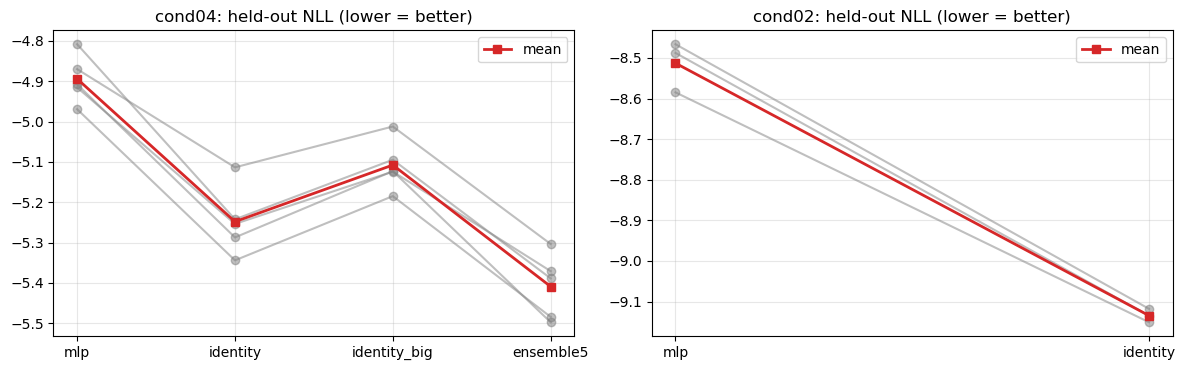

In [12]:
B = OUT / "benchmark"
nll = pd.concat([pd.read_csv(B / f"{d}_nll.csv") for d in ("cond04", "cond02")])
bm = pd.concat([pd.read_csv(B / f"{d}_metrics.csv") for d in ("cond04", "cond02")])

rows = []
for d, sub in nll.groupby("dataset"):
    w = sub.pivot(index="seed", columns="arm", values="nll")
    for arm in [a for a in ["identity", "identity_big", "ensemble5"] if a in w]:
        diff = w[arm] - w["mlp"]
        rows.append({"dataset": d, "arm": arm, "seeds": len(diff),
                     "NLL change vs mlp": diff.mean(), "SE": diff.std(ddof=1) / np.sqrt(len(diff)),
                     "better on all seeds": bool((diff < 0).all())})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, d in zip(axes, ["cond04", "cond02"]):
    w = nll[nll.dataset == d].pivot(index="seed", columns="arm", values="nll")
    arms = [a for a in ["mlp", "identity", "identity_big", "ensemble5"] if a in w]
    for _, r in w[arms].iterrows():
        ax.plot(arms, r.values, "o-", color="gray", alpha=0.5)
    ax.plot(arms, w[arms].mean().values, "s-", color="tab:red", lw=2, label="mean")
    ax.set_title(f"{d}: held-out NLL (lower = better)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [13]:
cols = ["r2", "calib_slope", "cover50", "cover90", "mean_sd", "edge_bias_low", "edge_bias_high"]
bm.groupby(["dataset", "parameter", "arm"])[cols].mean().round(3)

r2  calib_slope  cover50  cover90  mean_sd  edge_bias_low  edge_bias_high
dataset parameter       arm                                                                                       
cond02  am22            identity      0.799        1.026    0.496    0.889    0.054          0.096          -0.027
                        mlp           0.799        1.036    0.551    0.921    0.060          0.099          -0.032
        prop_h2_latent1 identity      0.804        0.999    0.487    0.901    0.068          0.062          -0.079
                        mlp           0.788        1.004    0.529    0.922    0.077          0.071          -0.097
        re              identity      0.839        1.029    0.489    0.880    0.066          0.080          -0.080
                        mlp           0.832        1.057    0.553    0.923    0.077          0.098          -0.090
        rg              identity      0.864        1.006    0.469    0.895    0.068          0.067          -0.055
                        mlp           0.859        1.079    0.532    0.921    0.080          0.092          -0.087
        vg1             identity      0.961        1.009    0.475    0.887    0.033          0.037          -0.015
                        mlp           0.955        1.027    0.546    0.939    0.043          0.048          -0.031
cond04  move_p          ensemble5     0.984        1.002    0.533    0.907    0.027          0.017          -0.011
                        identity      0.984        1.003    0.507    0.890    0.026          0.017          -0.011
                        identity_big  0.982        1.001    0.519    0.893    0.030          0.016          -0.015
                        mlp           0.977        1.013    0.626    0.951    0.041          0.023          -0.028
        prop_h2_latent1 ensemble5     0.808        1.026    0.480    0.880    0.070          0.069          -0.072
                        identity      0.798        1.028    0.478    0.867    0.071          0.074          -0.071
                        identity_big  0.797        1.033    0.490    0.868    0.071          0.072          -0.076
                        mlp           0.795        1.027    0.533    0.913    0.077          0.076          -0.076
        vg1             ensemble5     0.812        1.047    0.491    0.883    0.075          0.087          -0.053
                        identity      0.804        1.051    0.487    0.864    0.074          0.086          -0.056
                        identity_big  0.805        1.061    0.501    0.890    0.078          0.093          -0.054
                        mlp           0.798        1.070    0.533    0.909    0.084          0.097          -0.062

## 8. Conclusions

**All four parameters can be estimated together.** Under both simulation-based methods,
every one of the 15 subsets is identified, including the full set
{move_p, n_gen, vg1, prop_h2_latent1}. With all four free, NPE gives test R² = 0.98 (move_p),
0.79 (n_gen), 0.84 (vg1) and 0.81 (prop_h2_latent1), with posterior SDs 0.13-0.41 of the
prior SD. Ridge agrees (lowest R² 0.65, for n_gen).

**n_gen trades off mainly against move_p.** n_gen reaches R² 0.79-0.83 whenever move_p is
also free and 0.88-0.90 whenever move_p is known, while fixing vg1 or prop_h2_latent1 barely
changes it. Conversely, fixing n_gen helps the others only a little (vg1 0.84 → 0.87;
move_p 0.98 → 0.99). So if one parameter is to be fixed to sharpen n_gen, move_p is the one
that matters, not vg1 or prop_h2_latent1.

**The n_gen posterior is a proper distribution over counts.** It now comes from a categorical
classifier (probabilities for n_gen = 3, ..., 10), with the continuous parameters drawn from a
flow conditioned on n_gen. With all four free, the posterior mode is exactly right 47% of the
time and within ±1 most of the rest (log score -1.20, against -2.08 for a flat posterior); with
only n_gen free, the mode is right 64% of the time. Its 90% intervals cover 97-99%, which is
expected for a count: an interval can only grow in whole generations.

**The Jacobian is more pessimistic, and only because of its collinearity rule.** At the
baseline, n_gen and vg1 move the correlations in almost the same direction (cosine 0.98), and
move_p and n_gen nearly so (0.91). Every subset that contains either pair fails the
|cos| ≤ 0.90 rule, which leaves {move_p, vg1, prop_h2_latent1} and {n_gen, prop_h2_latent1} as
the largest subsets passing all three methods. But the Cramér-Rao SEs, which already account
for collinearity and noise, stay below 0.15 of the range in every subset, and the condition
number stays below 30: the pairs are strongly correlated but separable. The global methods do
better than the local cosine rule suggests because the effects are not linear over the full
ranges and the PGS correlations respond to vg1 much less than the phenotypic ones do, while
n_gen moves both.

**Where identification is weak.** n_gen is the hardest parameter, and it is only weakly
identified when migration is rare: in the all-four NPE, R² for n_gen is 0.11 when
move_p ≤ 0.1 (34 test simulations) and 0.87 above it. With little migration the islands barely sort on EA, so there is
little stratification for time to accumulate. Restricting move_p to ≥ 0.1 in production would
avoid most of that region.

**Dropping the embedding network does not hurt; it helps (Section 7).** With identical splits,
seeds and flows, feeding the standardised correlations straight into the flow beats the
production PgsPhenoEmbeddingNet (dropout 0.3) on the held-out proper scoring rule on every seed:
by 0.35 ± 0.03 nats on this design (5 seeds) and by 0.62 ± 0.03 nats on the production
condition-02 data (3 seeds, about 18,000 simulations). R² is equal or higher for every
parameter, posterior means are better calibrated (slope of truth on estimate closer to 1, e.g.
rg 1.08 → 1.01 on condition 02), edge bias is smaller, and training is about 40% faster. The
embedding's 90% intervals were too wide (0.92-0.95 coverage); without it they are close to
nominal on condition 02 (0.88-0.90) and slightly narrow on this smaller design (0.82-0.93).
An ensemble of 5 flows improves the score further (another 0.16 nats) and brings coverage closer
to 90%.

**The "known input" shortcut is fair.** For the best 3-parameter subset {move_p, vg1,
prop_h2_latent1}, truly fixing n_gen at 6 (600 new simulations) and giving it as a known input
(600 design rows) give similar results: R² 0.99 vs 0.99 (move_p), 0.79 vs 0.85 (vg1) and
0.74 vs 0.77 (prop_h2_latent1). Each test set is only 90 rows, so differences of this size are
within noise.

**Caveats.** These are small simulations (population 4,000, 300 causal variants, 2,000
conditions); production-size runs (population 40,000) give less noisy correlations and should
identify the parameters at least as well. n_gen = 3 observes the founders and loses the PPSCC
feature, which is why PPSCC and HSFS (no half-siblings without remating) were dropped.

**Recommendation.** Keep all four parameters free in the production condition 04, or, if one
must be fixed to sharpen n_gen, fix move_p. Consider narrowing move_p to 0.1-0.7 so that n_gen
stays estimable. Use the mixed estimator for n_gen and drop the embedding network; consider a
small ensemble for better-calibrated intervals.
